In [1]:
# !pip install -U ultralytics pillow opencv-python pandas matplotlib tqdm
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from ultralytics import RTDETR, YOLOE
from ultralytics.models.yolo.yoloe import YOLOEVPSegPredictor

print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch: 2.12.1+cu132 | CUDA: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [2]:
VIDEO_PATH = "sample.mp4"

DEVICE = 0 if torch.cuda.is_available() else "cpu"

# --- detector / tracker ---
WEIGHTS = "rtdetr-x.pt"          # or "rtdetr-l.pt"
CONF    = 0.15                   # low on purpose: keep partly hidden people
IOU     = 0.70
IMGSZ   = 960

tracker_yaml = """
tracker_type: botsort
track_high_thresh: 0.20
track_low_thresh: 0.05
new_track_thresh: 0.25
track_buffer: 200
match_thresh: 0.8
fuse_score: True
gmc_method: none
proximity_thresh: 0.5
appearance_thresh: 0.8
with_reid: True
model: auto
"""
Path("botsort_custom.yaml").write_text(tracker_yaml)
TRACKER_CFG = "botsort_custom.yaml"

# --- seeds: the two reference moments ---
SEED_A_SECOND   = 18             # white top
SEED_B_SECOND   = 34             # black jacket
PREVIEW_SECONDS = [SEED_A_SECOND, SEED_B_SECOND]

# --- tag scoring (YOLOE visual prompt) ---
YOLOE_WEIGHTS    = "yoloe-11l-seg.pt"   # or "yoloe-11s-seg.pt" if VRAM is tight
MIN_TRACKLET_LEN = 8             # ignore fragments shorter than this (frames)
N_SAMPLES        = 15            # frames scored per tracklet
TORSO_SCALE      = 3             # upscale factor of torso crop
TAG_PAD          = 0.30          # padding around the tag crop (display only)

# --- stitching ---
MAX_GAP          = 300           # max frames between linked fragments (12 s at 25 fps)
SHORT_GAP        = 25            # gaps this short can link by motion alone (1 s)
V_MAX            = 10            # max person speed, px per frame
GATE_BASE_H      = 0.5           # base search radius as fraction of person height
TAG_ACCEPT_RATIO = 0.7           # long-gap links need tag score >= ratio * seed tag score
ANCHOR_BONUS     = 1.0           # extra score for linking into the other seed tracklet
W_TAG, W_SPACE, W_GAP = 1.0, 0.5, 0.2

In [3]:
cap = cv2.VideoCapture(VIDEO_PATH)
assert cap.isOpened(), f"Cannot open {VIDEO_PATH}"
FPS      = cap.get(cv2.CAP_PROP_FPS)
N_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W        = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H        = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()
print(f"{W}x{H} | {FPS:.2f} fps | {N_FRAMES} frames | {N_FRAMES / FPS:.1f} s")

960x720 | 25.00 fps | 1341 frames | 53.6 s


In [4]:
model = RTDETR(WEIGHTS)
print("Loaded:", WEIGHTS)

Loaded: rtdetr-x.pt


In [5]:
tracks = {}             # frame -> [(id, x1, y1, x2, y2, conf), ...]
tracklet_boxes = {}     # id -> {frame: (x1, y1, x2, y2)}

results = model.track(
    source=VIDEO_PATH, stream=True, persist=True,
    tracker=TRACKER_CFG, classes=[0],
    conf=CONF, iou=IOU, imgsz=IMGSZ, device=DEVICE, verbose=False,
)

for i, r in enumerate(tqdm(results, total=N_FRAMES)):
    rows = []
    if r.boxes is not None and r.boxes.id is not None:
        xyxy = r.boxes.xyxy.cpu().numpy()
        ids  = r.boxes.id.int().cpu().numpy()
        conf = r.boxes.conf.cpu().numpy()
        for b, tid, c in zip(xyxy, ids, conf):
            tid = int(tid)
            rows.append((tid, float(b[0]), float(b[1]), float(b[2]), float(b[3]), float(c)))
            tracklet_boxes.setdefault(tid, {})[i] = (float(b[0]), float(b[1]), float(b[2]), float(b[3]))
    tracks[i] = rows

# free GPU memory before loading the next model
del model
torch.cuda.empty_cache()

print("Frames processed:", len(tracks), "| tracklets (IDs):", len(tracklet_boxes))
summary = pd.DataFrame(
    [(t, min(f), max(f), len(f)) for t, f in tracklet_boxes.items()],
    columns=["id", "first", "last", "n"]).sort_values("first")
summary["start_s"] = summary["first"] / FPS
summary["end_s"]   = summary["last"] / FPS
summary.head(30)

  0%|          | 0/1341 [00:00<?, ?it/s]

Frames processed: 1341 | tracklets (IDs): 412


,id,first,last,n,start_s,end_s
0,1,0,457,333,0.00,18.28
1,2,4,69,61,0.16,2.76
2,3,4,890,793,0.16,35.60
3,5,5,23,13,0.20,0.92
4,6,7,43,30,0.28,1.72
5,7,8,71,61,0.32,2.84
6,8,9,60,39,0.36,2.40
7,9,10,18,9,0.40,0.72
8,10,12,17,6,0.48,0.68
9,11,12,155,124,0.48,6.20


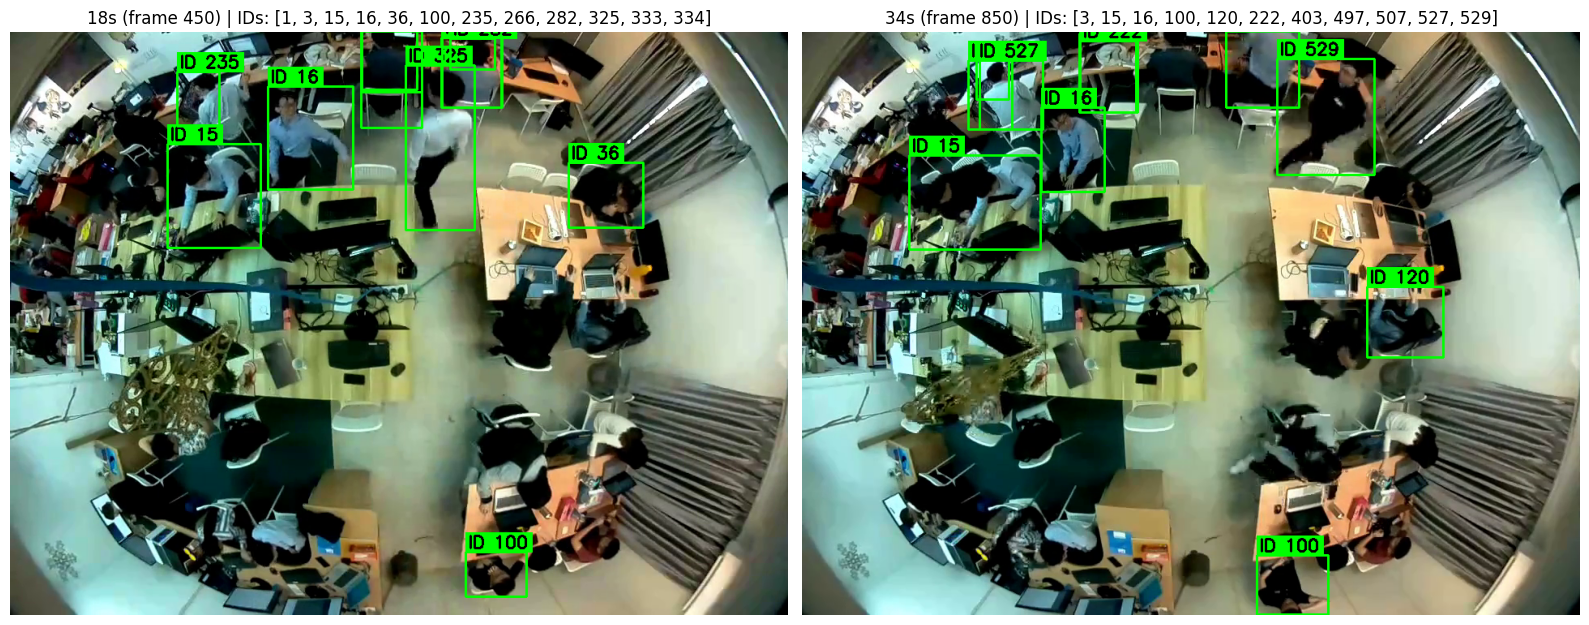

In [6]:
def read_frame(idx):
    c = cv2.VideoCapture(VIDEO_PATH)
    c.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, fr = c.read()
    c.release()
    return fr if ok else None

def draw_ids(frame, rows):
    img = frame.copy()
    for tid, x1, y1, x2, y2, c in rows:
        p1, p2 = (int(x1), int(y1)), (int(x2), int(y2))
        cv2.rectangle(img, p1, p2, (0, 255, 0), 2)
        label = f"ID {tid}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
        cv2.rectangle(img, (p1[0], p1[1] - th - 8), (p1[0] + tw + 6, p1[1]), (0, 255, 0), -1)
        cv2.putText(img, label, (p1[0] + 3, p1[1] - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
    return img

fig, axes = plt.subplots(1, len(PREVIEW_SECONDS), figsize=(8 * len(PREVIEW_SECONDS), 7))
axes = np.atleast_1d(axes)
for ax, sec in zip(axes, PREVIEW_SECONDS):
    idx = min(int(round(sec * FPS)), N_FRAMES - 1)
    ax.imshow(cv2.cvtColor(draw_ids(read_frame(idx), tracks.get(idx, [])), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{sec}s (frame {idx}) | IDs: {sorted(r[0] for r in tracks.get(idx, []))}")
    ax.axis("off")
plt.tight_layout(); plt.show()

Employee's ID at 18 s (white top):  325
Employee's ID at 34 s (black jacket):  529


Crop A frame: 450 | size (w, h): (255, 261)
Crop B frame: 850 | size (w, h): (360, 186)


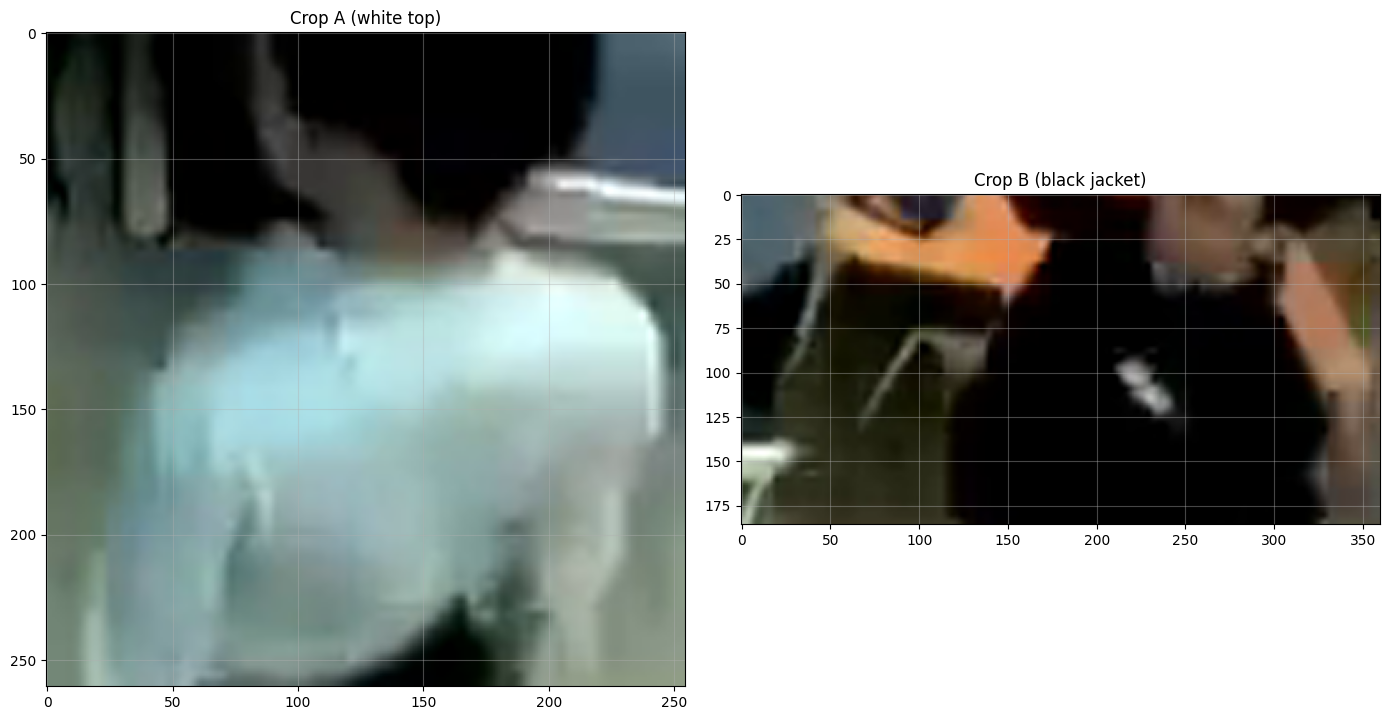

In [7]:
def torso_crop(frame, box, scale=TORSO_SCALE):
    """Upper-body region of a person box, upscaled, returned as a PIL image."""
    x1, y1, x2, y2 = box
    h = y2 - y1
    cx1, cx2 = max(0, int(x1)), min(W, int(x2))
    cy1, cy2 = max(0, int(y1 + 0.12 * h)), min(H, int(y1 + 0.55 * h))
    crop = frame[cy1:cy2, cx1:cx2]
    if crop.size == 0:
        return None
    crop = cv2.resize(crop, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    return Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))

SEED_A_ID = int(input(f"Employee's ID at {SEED_A_SECOND} s (white top): "))
SEED_B_ID = int(input(f"Employee's ID at {SEED_B_SECOND} s (black jacket): "))
for name, sid in (("A", SEED_A_ID), ("B", SEED_B_ID)):
    assert sid in tracklet_boxes, f"Seed {name}: ID {sid} does not exist, check Cell 5."

def pick_seed(tid, second):
    """Frame of this ID closest to the requested second."""
    f = min(tracklet_boxes[tid], key=lambda f: abs(f - second * FPS))
    if abs(f - second * FPS) > FPS:
        print(f"WARNING: ID {tid} is not visible near {second}s, using frame {f} ({f / FPS:.1f}s)")
    return f, tracklet_boxes[tid][f]

seed_A_frame, seed_A_box = pick_seed(SEED_A_ID, SEED_A_SECOND)
seed_B_frame, seed_B_box = pick_seed(SEED_B_ID, SEED_B_SECOND)
seed_A_img = torso_crop(read_frame(seed_A_frame), seed_A_box)
seed_B_img = torso_crop(read_frame(seed_B_frame), seed_B_box)
print("Crop A frame:", seed_A_frame, "| size (w, h):", seed_A_img.size)
print("Crop B frame:", seed_B_frame, "| size (w, h):", seed_B_img.size)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, img, title in ((axes[0], seed_A_img, "Crop A (white top)"),
                       (axes[1], seed_B_img, "Crop B (black jacket)")):
    ax.imshow(img); ax.grid(True, alpha=0.4); ax.set_title(title)
plt.tight_layout(); plt.show()

Tag box in crop A (x1,y1,x2,y2):  100,100,150,150
Tag box in crop B (x1,y1,x2,y2):  200,75,250,125


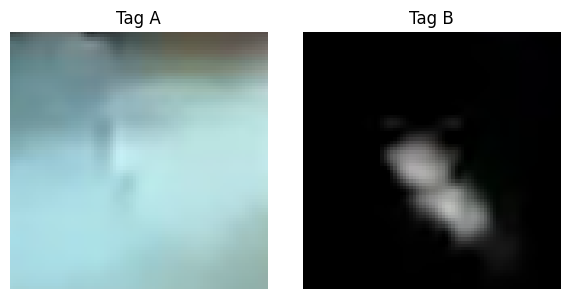

In [8]:
def read_box(label, img):
    x1, y1, x2, y2 = map(int, input(f"Tag box in crop {label} (x1,y1,x2,y2): ").split(","))
    assert 0 <= x1 < x2 <= img.width and 0 <= y1 < y2 <= img.height, "Box outside the crop"
    return (x1, y1, x2, y2)

tag_A_box = read_box("A", seed_A_img)
tag_B_box = read_box("B", seed_B_img)

# display only: check the boxes really contain the tag
def pad_crop(img, box, pad=TAG_PAD):
    x1, y1, x2, y2 = box
    pw, ph = int((x2 - x1) * pad), int((y2 - y1) * pad)
    return img.crop((max(0, x1 - pw), max(0, y1 - ph),
                     min(img.width, x2 + pw), min(img.height, y2 + ph)))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax, img, box, title in ((axes[0], seed_A_img, tag_A_box, "Tag A"),
                            (axes[1], seed_B_img, tag_B_box, "Tag B")):
    ax.imshow(pad_crop(img, box)); ax.axis("off"); ax.set_title(title)
plt.tight_layout(); plt.show()

In [9]:
def make_tag_model(refer_img, box):
    """YOLOE with the tag as its only class, defined by a reference image + box."""
    m = YOLOE(YOLOE_WEIGHTS)
    refer_bgr = cv2.cvtColor(np.array(refer_img), cv2.COLOR_RGB2BGR)
    vp = dict(bboxes=np.array([list(box)], dtype=float), cls=np.array([0]))
    m.predict(refer_bgr, refer_image=refer_bgr, visual_prompts=vp,
              predictor=YOLOEVPSegPredictor, imgsz=640, device=DEVICE, verbose=False)
    return m

yoloe_A = make_tag_model(seed_A_img, tag_A_box)
yoloe_B = make_tag_model(seed_B_img, tag_B_box)

@torch.no_grad()
def _best_conf(m, torso_img):
    bgr = cv2.cvtColor(np.array(torso_img), cv2.COLOR_RGB2BGR)
    r = m.predict(bgr, conf=0.001, imgsz=640, device=DEVICE, verbose=False)[0]
    return float(r.boxes.conf.max()) if r.boxes is not None and len(r.boxes) else 0.0

def tag_scores_AB(torso_img):
    """(score against tag A reference, score against tag B reference)."""
    return _best_conf(yoloe_A, torso_img), _best_conf(yoloe_B, torso_img)

# Sanity checks
sAA, sAB = tag_scores_AB(seed_A_img)
sBA, sBB = tag_scores_AB(seed_B_img)
print(f"Crop A: model A = {sAA:.3f} (should be high) | model B = {sAB:.3f}")
print(f"Crop B: model A = {sBA:.3f}                  | model B = {sBB:.3f} (should be high)")

Crop A: model A = 0.026 (should be high) | model B = 0.002
Crop B: model A = 0.001                  | model B = 0.084 (should be high)


In [10]:
eligible = [t for t, f in tracklet_boxes.items() if len(f) >= MIN_TRACKLET_LEN]
assert SEED_A_ID in eligible and SEED_B_ID in eligible, \
    "A seed tracklet is shorter than MIN_TRACKLET_LEN, lower it in Cell 1."

# choose up to N_SAMPLES evenly spaced frames per tracklet
need = {}   # frame -> [ids to score]
for tid in eligible:
    frames = sorted(tracklet_boxes[tid])
    pick = np.linspace(0, len(frames) - 1, min(N_SAMPLES, len(frames))).astype(int)
    for k in pick:
        need.setdefault(frames[k], []).append(tid)

scores_A = {t: [] for t in eligible}
scores_B = {t: [] for t in eligible}

cap = cv2.VideoCapture(VIDEO_PATH)
for f in tqdm(range(N_FRAMES)):
    ok, frame = cap.read()
    if not ok:
        break
    if f not in need:
        continue
    for tid in need[f]:
        img = torso_crop(frame, tracklet_boxes[tid][f])
        if img is None:
            continue
        sA, sB = tag_scores_AB(img)
        scores_A[tid].append(sA)
        scores_B[tid].append(sB)
cap.release()

best_A  = {t: (max(v) if v else 0.0) for t, v in scores_A.items()}
best_B  = {t: (max(v) if v else 0.0) for t, v in scores_B.items()}
tag_best = {t: max(best_A[t], best_B[t]) for t in eligible}

rank_df = pd.DataFrame({"A": best_A, "B": best_B, "best": tag_best}).sort_values("best", ascending=False)
ranks = list(rank_df.index)
print(f"Seed A (ID {SEED_A_ID}) rank: {ranks.index(SEED_A_ID) + 1} | "
      f"Seed B (ID {SEED_B_ID}) rank: {ranks.index(SEED_B_ID) + 1}")
rank_df.head(15).round(3)

  0%|          | 0/1341 [00:00<?, ?it/s]

Seed A (ID 325) rank: 12 | Seed B (ID 529) rank: 1


,A,B,best
529,0.010,0.084,0.084
577,0.036,0.006,0.036
266,0.034,0.007,0.034
120,0.004,0.034,0.034
507,0.007,0.033,0.033
372,0.032,0.022,0.032
258,0.032,0.016,0.032
17,0.031,0.020,0.031
39,0.005,0.031,0.031
812,0.013,0.031,0.031


In [11]:
def foot(b):
    return np.array([(b[0] + b[2]) / 2, b[3]])

info = {}
for tid in eligible:
    fr = sorted(tracklet_boxes[tid])
    info[tid] = dict(id=tid, start=fr[0], end=fr[-1],
                     b_start=tracklet_boxes[tid][fr[0]], b_end=tracklet_boxes[tid][fr[-1]])

SEEDS = {SEED_A_ID, SEED_B_ID}
TAG_ACCEPT = TAG_ACCEPT_RATIO * min(tag_best[SEED_A_ID], tag_best[SEED_B_ID])
print(f"Seed tag scores: A = {tag_best[SEED_A_ID]:.3f} | B = {tag_best[SEED_B_ID]:.3f}")
print(f"TAG_ACCEPT threshold for long-gap links: {TAG_ACCEPT:.3f}")

def link_score(cur, cand, direction):
    if direction == "fwd":
        gap = cand["start"] - cur["end"]
        p_from, p_to, b = foot(cur["b_end"]), foot(cand["b_start"]), cur["b_end"]
    else:
        gap = cur["start"] - cand["end"]
        p_from, p_to, b = foot(cur["b_start"]), foot(cand["b_end"]), cur["b_start"]
    if gap < 1 or gap > MAX_GAP:
        return None
    dist = float(np.linalg.norm(p_from - p_to))
    allowed = GATE_BASE_H * (b[3] - b[1]) + V_MAX * gap
    if dist > allowed:
        return None                                   # physically unreachable
    tag = tag_best[cand["id"]]
    if gap > SHORT_GAP and tag < TAG_ACCEPT:
        return None                                   # long gap needs tag evidence
    return W_TAG * tag + W_SPACE * (1 - dist / allowed) - W_GAP * gap / MAX_GAP

members = set()   # tracklets already placed in the target's chain

def extend(seed, direction):
    chain, cur = [], info[seed]
    while True:
        best = None
        for tid, cand in info.items():
            if tid in members or tid == cur["id"]:
                continue
            s = link_score(cur, cand, direction)
            if s is None:
                continue
            if tid in SEEDS:
                s += ANCHOR_BONUS                     # user-confirmed target tracklet
            if best is None or s > best[0]:
                best = (s, tid)
        if best is None:
            break
        members.add(best[1]); chain.append(best[1]); cur = info[best[1]]
    return chain

# earlier seed first, then the later seed
first_seed, second_seed = ((SEED_A_ID, SEED_B_ID) if seed_A_frame <= seed_B_frame
                           else (SEED_B_ID, SEED_A_ID))

members.add(first_seed)
fwd_chain = extend(first_seed, "fwd")      # may reach the second seed by stitching
extend(first_seed, "bwd")

if first_seed == second_seed:
    seeds_linked = True
elif second_seed in members:
    seeds_linked = True                    # reached from the first seed
else:
    seeds_linked = False                   # not reachable: extend from the second seed separately
    members.add(second_seed)
    extend(second_seed, "fwd")
    extend(second_seed, "bwd")

print("Seed A and seed B linked into one chain by stitching:", "yes" if seeds_linked else "no")

chain_ids = sorted(members, key=lambda t: info[t]["start"])
pd.DataFrame([{
    "id": t,
    "start_s": round(info[t]["start"] / FPS, 1),
    "end_s": round(info[t]["end"] / FPS, 1),
    "frames": len(tracklet_boxes[t]),
    "tag_A": round(best_A[t], 3), "tag_B": round(best_B[t], 3),
    "seed": "A" if t == SEED_A_ID else ("B" if t == SEED_B_ID else ""),
} for t in chain_ids])

Seed tag scores: A = 0.028 | B = 0.084
TAG_ACCEPT threshold for long-gap links: 0.020
Seed A and seed B linked into one chain by stitching: yes


,id,start_s,end_s,frames,tag_A,tag_B,seed
0,39,1.6,7.2,111,0.005,0.031,
1,258,14.4,15.7,33,0.032,0.016,
2,325,17.8,18.3,14,0.028,0.004,A
3,355,19.0,19.7,17,0.008,0.002,
4,362,19.8,26.2,9,0.006,0.005,
5,529,33.1,34.6,38,0.010,0.084,B
6,678,42.1,42.7,13,0.016,0.029,
7,714,46.1,48.2,12,0.024,0.009,
8,812,50.8,51.6,17,0.013,0.031,
9,841,52.4,53.6,25,0.006,0.007,


In [12]:
def xy(box):
    x1, y1, x2, y2 = box
    return (round((x1 + x2) / 2, 1), round((y1 + y2) / 2, 1)), (round((x1 + x2) / 2, 1), round(y2, 1))

print("Seed frames used:")
for name, sid, f, box in (("A", SEED_A_ID, seed_A_frame, seed_A_box),
                          ("B", SEED_B_ID, seed_B_frame, seed_B_box)):
    c, ft = xy(box)
    print(f"  Seed {name}: ID {sid} | frame {f} ({f / FPS:.2f}s) | center={c} | foot={ft}")

print("\nLock report:")
prev_end = None
for k, tid in enumerate(chain_ids):
    inf = info[tid]
    c, ft = xy(inf["b_start"])
    label = "LOCK   " if k == 0 else "RE-LOCK"
    gap_txt = "" if prev_end is None else f" | gap since last seen: {inf['start'] - prev_end} frames"
    print(f"{label} | frame {inf['start']} ({inf['start'] / FPS:.2f}s) | tracklet {tid} "
          f"| center={c} | foot={ft}{gap_txt}")

    c, ft = xy(inf["b_end"])
    print(f"LOST    | frame {inf['end']} ({inf['end'] / FPS:.2f}s) | tracklet {tid} "
          f"| center={c} | foot={ft}")
    prev_end = inf["end"]

tracked = sum(len(tracklet_boxes[t]) for t in chain_ids)
print(f"\nTarget detected in {tracked} of {N_FRAMES} frames "
      f"(first lock {info[chain_ids[0]]['start']}, last seen {info[chain_ids[-1]]['end']}, "
      f"video ends at frame {N_FRAMES - 1})")

Seed frames used:
  Seed A: ID 325 | frame 450 (18.00s) | center=(530.7, 144.4) | foot=(530.7, 245.8)
  Seed B: ID 529 | frame 850 (34.00s) | center=(646.6, 105.9) | foot=(646.6, 177.6)

Lock report:
LOCK    | frame 39 (1.56s) | tracklet 39 | center=(646.5, 353.5) | foot=(646.5, 418.1)
LOST    | frame 179 (7.16s) | tracklet 39 | center=(643.0, 359.5) | foot=(643.0, 419.0)
RE-LOCK | frame 361 (14.44s) | tracklet 258 | center=(577.3, 302.7) | foot=(577.3, 370.9) | gap since last seen: 182 frames
LOST    | frame 393 (15.72s) | tracklet 258 | center=(567.7, 326.4) | foot=(567.7, 377.5)
RE-LOCK | frame 444 (17.76s) | tracklet 325 | center=(567.5, 255.4) | foot=(567.5, 330.5) | gap since last seen: 51 frames
LOST    | frame 457 (18.28s) | tracklet 325 | center=(444.9, 80.4) | foot=(444.9, 160.7)
RE-LOCK | frame 474 (18.96s) | tracklet 355 | center=(470.6, 59.2) | foot=(470.6, 117.6) | gap since last seen: 17 frames
LOST    | frame 492 (19.68s) | tracklet 355 | center=(468.3, 41.3) | foot=(46

In [14]:
from IPython.display import Video

OUT_DIR = Path("output"); OUT_DIR.mkdir(exist_ok=True)
OUT_VIDEO = str(OUT_DIR / "target_result0.mp4")

SHOW_INTERPOLATED = False      # True: draw a yellow guessed box across gaps between fragments
BANNER_FRAMES = int(FPS * 1.5) # how long the LOCKED / LOST banner stays on screen

# ---- per-frame lookup of the target box ----
frame_box = {}   # frame -> (tracklet_id, box, kind)
for tid in chain_ids:
    for f, b in tracklet_boxes[tid].items():
        frame_box[f] = (tid, b, "detected")

if SHOW_INTERPOLATED:
    for a, b in zip(chain_ids[:-1], chain_ids[1:]):
        f0, f1 = info[a]["end"], info[b]["start"]
        b0, b1 = np.array(info[a]["b_end"]), np.array(info[b]["b_start"])
        for f in range(f0 + 1, f1):
            t = (f - f0) / (f1 - f0)
            frame_box[f] = (-1, tuple((1 - t) * b0 + t * b1), "interpolated")

# ---- event frames for the banners ----
events = {}      # frame -> banner text
for k, tid in enumerate(chain_ids):
    events[info[tid]["start"]] = "LOCKED" if k == 0 else "RE-LOCKED"
    events.setdefault(info[tid]["end"], "LOST")

# ---- drawing helpers ----
def put_label(img, text, org, bg, fg=(255, 255, 255), scale=0.7, thick=2):
    (tw, th), base = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, thick)
    x, y = int(org[0]), int(org[1])
    cv2.rectangle(img, (x, y - th - base - 4), (x + tw + 8, y + 2), bg, -1)
    cv2.putText(img, text, (x + 4, y - base), cv2.FONT_HERSHEY_SIMPLEX, scale, fg, thick)

# ---- video writer (try H.264 first, fall back to mp4v) ----
writer = cv2.VideoWriter(OUT_VIDEO, cv2.VideoWriter_fourcc(*"avc1"), FPS, (W, H))
if not writer.isOpened():
    writer = cv2.VideoWriter(OUT_VIDEO, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
assert writer.isOpened(), "Could not open the video writer"

banner_text, banner_until = "", -1
n_detected = n_interp = n_searching = 0

cap = cv2.VideoCapture(VIDEO_PATH)
for f in tqdm(range(N_FRAMES)):
    ok, frame = cap.read()
    if not ok:
        break

    if f in events:
        banner_text, banner_until = events[f], f + BANNER_FRAMES

    if f in frame_box:
        tid, (x1, y1, x2, y2), kind = frame_box[f]
        if kind == "detected":
            color = (0, 0, 255)                  # red
            label = f"TARGET | trk {tid}"
            n_detected += 1
        else:
            color = (0, 255, 255)                # yellow
            label = "TARGET (estimated)"
            n_interp += 1
        cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), color, 3)
        put_label(frame, label, (x1, max(26, y1 - 4)), bg=color,
                  fg=(255, 255, 255) if kind == "detected" else (0, 0, 0))
    else:
        n_searching += 1
        put_label(frame, "SEARCHING...", (10, 60), bg=(80, 80, 80))

    put_label(frame, f"frame {f} | {f / FPS:.2f}s", (10, 28), bg=(0, 0, 0), scale=0.6, thick=1)

    if f <= banner_until and banner_text:
        bcolor = {"LOCKED": (0, 160, 0), "RE-LOCKED": (0, 160, 0), "LOST": (0, 0, 200)}[banner_text]
        put_label(frame, banner_text, (W // 2 - 60, 40), bg=bcolor, scale=0.9, thick=2)

    writer.write(frame)

cap.release()
writer.release()

print("Saved:", OUT_VIDEO)
print(f"Frames with target box: {n_detected} detected, {n_interp} estimated | "
      f"frames searching (no box): {n_searching}")
Video(OUT_VIDEO, embed=False, width=800)

  0%|          | 0/1341 [00:00<?, ?it/s]

Saved: output\target_result0.mp4
Frames with target box: 289 detected, 0 estimated | frames searching (no box): 1052
